# Lab: Visualizing Text Data

Select **two distinct text datasets**. Ask **one research question for each dataset** and answer it using the six-step reproducible analysis workflow. Create **two different types of figures for each question**, for a total of two research questions and four figures.

Each pair of figures should provide complementary evidence about the text. You may use Seaborn, Matplotlib, Plotly Express, or WordCloud. Choose datasets whose language is **work appropriate**.


## Learning goals

- Select and document usable text datasets.
- Ask focused questions about vocabulary, text length, or differences between groups.
- Prepare text reproducibly while preserving original wording for context checks.
- Choose and interpret two complementary figures per question.
- Distinguish word occurrences from the number or percentage of documents containing a word.
- Support conclusions with checked evidence and explain the limitations of the data and displays.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each dataset. Inspect missing values during Data; use Check to investigate the actual figures and calculations. Use separate code cells for individual operations and add cells as needed.


## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code, reading the source documentation, and checking every claim against your output. Complete the AI-use reflection at the end.


## Select your two datasets

Each dataset needs:

- A documented source and definitions for the features you use.
- Actual text, such as headlines, posts, descriptions, reviews, or passages—not only ratings or precomputed sentiment scores.
- Enough separate documents or passages to support your question. Define what one row represents.
- Relevant group labels if you plan to compare categories, authors, sources, or ratings. Document any groups you create.

Use two distinct datasets, not two filters of the same collection. A comparison of two categories from one collection counts as **one dataset and one investigation**. Choose your own questions rather than repeating the SMS lecture. Other documented sources are welcome.

Choose a manageable subset before analysis and document any sampling and its random seed. Save fixed copies in this notebook's `data` folder and use relative paths. Preserve the original text alongside prepared features. If you assemble passages from books, document their boundaries and retain book and author identifiers; passages from one book are not independent samples of all literature.

### Work-appropriate language

Be mindful that your datasets should be **work appropriate** for a classroom presentation. Read sample records and review the words, excerpts, and hover text that your figures will display. Public availability does not guarantee appropriate content. Choose another source or document any content-based exclusions when needed; explain how screening may affect your results. Review the final outputs before submitting. The suggestions below have not been screened for you.


### Candidate datasets

| Candidate and source | Useful text and grouping information | Possible question and figure pair |
| --- | --- | --- |
| [UCI News Aggregator](https://archive.ics.uci.edu/dataset/359/news+aggregator) | News titles, category, publisher, and story identifiers. Use `newsCorpora.csv` and its README; analyze titles rather than assuming the file contains full articles. Start with two categories and a manageable sample. | How does vocabulary differ between business and science/technology headlines? Use a word-frequency bar chart and a word-frequency scatter plot. Repeated coverage of the same story may affect counts. |
| [20 Newsgroups through scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_20newsgroups.html) | Posts and topic labels. Consider `rec.sport.baseball` and `sci.space`. The loader supports selecting categories and removing headers, footers, and quoted replies. Save the selected text and labels locally. | How do vocabulary and post length differ between baseball and space discussions? Use grouped word-frequency bars and a text-length box plot. Screen the posts; topic selection does not guarantee clean language. |
| [Project Gutenberg](https://www.gutenberg.org/) | Downloadable books with author and title information. Assemble a collection of clearly defined passages or chapters from selected books and preserve their source identifiers. Remove book headers and license boilerplate from the analysis copy. | Which words characterize selected adventure and nature-writing books? Use word clouds and a grouped word-frequency chart. Multiple books per group support a broader comparison than one book per group. |

Adapt the question to the available fields. A second pair of categories from the same collection does not satisfy the second-dataset requirement. The questions and chart pairs are starting points, not required choices.


## Choose two complementary figures per question

Choose **different chart types**, not two versions differing only in color, title, selected words, or counts versus percentages. You may reuse a chart type for the second dataset. A group of word clouds counts as one figure type; it cannot supply both figures by itself. At least one figure per question must support a numerical comparison, such as a bar chart, scatter plot, box plot, or heatmap.

| Figure | Tools | What it can help you see |
| --- | --- | --- |
| Word cloud | `WordCloud` and Matplotlib | An initial impression of prominent vocabulary. Each cloud scales its own words; font sizes are not precise comparisons across clouds. |
| Word-frequency bar chart | `sns.barplot()` or `px.bar()` | Exact occurrences or the percentage of documents containing selected words. State the denominator and use the same word selection across groups. |
| Word-frequency scatter plot | `px.scatter()` | Each point is a word, with its document percentage in group A on x and group B on y. Use equal scales and an equal-percentage reference line. |
| Text-length box plot or histogram | `sns.boxplot()`, `sns.histplot()`, `px.box()`, or `px.histogram()` | How document lengths vary within or across groups. Define length in words or characters. Length alone does not measure sentiment or quality. |
| Word-by-group heatmap—an additional option | `sns.heatmap()` or `px.imshow()` | How the percentage of documents containing a word varies across several groups. Use one common color scale and state its units. |

Keep different measures in separate figures. Explain how each figure helps answer the same research question. A plot of group sizes is useful context, but it cannot replace a required text-analysis figure unless it directly answers your question about the text.


### Preparation and interpretation guidance

- Preserve an original-text column and a document identifier. Decide how to handle blank text, duplicates, URLs, punctuation, case, and boilerplate.
- Start with scikit-learn's `ENGLISH_STOP_WORDS` for English text, then use an editable `additional_stopwords` list as in the lecture. Justify additions and apply the same choices to compared groups. Other languages need appropriate preparation.
- Report how many documents are in each group. Unequal numbers of documents and different document lengths affect raw word counts.
- **Word occurrences** count every repetition. **Percent of documents containing a word** counts each document once, divided by all documents in that group, including documents without the word. This is not the percentage of a word's matches that belong to a group.
- Define and document any display threshold or top-word selection. A word absent from the displayed chart is not necessarily absent from the data.
- Use descriptive titles, readable labels, common scales for common measures, and useful hover information where applicable. Keep counts and percentages on separate figures.
- Reuse or adapt the lecture's preparation and sample-message function, explaining your changes. No classifier, sentiment model, or train/test split is required.


### Starting pattern for an additional chart type

This is an **adaptation example**, not code to run unchanged. It assumes `tokens_df` has one row per retained word occurrence, with `document_id`, `group`, and `word`, and `documents_df` has one row per document. Replace these names with yours.

```python
# Count each document once per word, even if the word repeats.
word_counts = tokens_df.groupby(['group', 'word'])['document_id'].nunique().reset_index(name='documents_with_word')
group_sizes = documents_df.groupby('group')['document_id'].nunique()
word_counts['percent_documents'] = 100 * word_counts['documents_with_word'] / word_counts['group'].map(group_sizes)

# Show the ten words occurring in the most documents overall.
selected_words = tokens_df.groupby('word')['document_id'].nunique().nlargest(10).index
grid = word_counts.pivot(index='word', columns='group', values='percent_documents')
grid = grid.reindex(index=selected_words, columns=group_sizes.index).fillna(0)
sns.heatmap(grid, annot=True, fmt='.1f', cmap='Blues',
            cbar_kws={'label': 'Percent of documents in each group containing the word'})
plt.xlabel('Group')
plt.ylabel('Word')
plt.title('Selected vocabulary across groups')
plt.show()
```

Use unique document IDs across the collection. Here zero means no retained occurrence was observed in a group with documents; it does not replace missing source text. Choose a manageable number of words and groups so labels remain readable.


In [1]:
# Import the libraries needed for your chosen figures and text preparation.
import html
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

DATA_DIR = Path('data')
BLUE, ORANGE, GRAY, INK = '#2a78d6', '#eb6834', '#a3a29c', '#52514e'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold'})

In [2]:
# Shared text preparation adapted from the SMS lecture. Both investigations use these functions.
# Contractions are function words, like the stopwords they shorten, but ENGLISH_STOP_WORDS does not list them.
CONTRACTIONS = ["don't", "didn't", "can't", "i'm", "wasn't", "couldn't", "i've", "wouldn't", "you're",
                "you'll", "doesn't", "won't", "weren't", "aren't", "isn't", "i'd", "they're", "we've",
                "i'll", "we're", "we'd", "they'd", "you've", "they've", "hadn't", "hasn't", "haven't",
                "shouldn't", "we'll", "they'll", "you'd"]


def prepare_text(text):
    """Repair HTML entities and curly apostrophes, lowercase, and remove URLs and HTML tags."""
    return (text.map(html.unescape)
            .str.replace('’', "'", regex=False)
            .str.lower()
            .str.replace(r'https?://\S+|www\.\S+', ' ', regex=True)
            .str.replace(r'<[^>]*>', ' ', regex=True))


def make_tokens(documents, id_col, group_col, extra_stopwords):
    """Return one row per retained word occurrence with its document ID and group."""
    words = documents['prepared_text'].str.findall(r"\b[a-z']+\b")
    tokens = documents[[id_col, group_col]].assign(word=words).explode('word').dropna(subset=['word'])
    tokens['word'] = tokens['word'].str.strip("'").str.replace(r"'s$", '', regex=True)
    stopwords = set(ENGLISH_STOP_WORDS).union(CONTRACTIONS, extra_stopwords)
    keep = ~tokens['word'].isin(stopwords) & tokens['word'].str.len().ge(3)
    return tokens.loc[keep].reset_index(drop=True)


def percent_documents(tokens, documents, id_col, group_col):
    """Percent of documents in each group that contain each word at least once."""
    with_word = tokens.groupby(['word', group_col])[id_col].nunique().unstack(group_col, fill_value=0)
    group_sizes = documents.groupby(group_col)[id_col].nunique()
    return 100 * with_word / group_sizes


def show_examples(data, text_col, group_col, word, n=2, seed=42, window=200):
    """Print up to n original texts per group that contain the word, centered on its first use.
    Adapted from the lecture's sample function: it samples within each group and shows the word in context."""
    pattern = rf'\b{re.escape(word)}\b'
    matches = data.loc[data['prepared_text'].str.contains(pattern, regex=True)]
    for group, rows in matches.groupby(group_col):
        print(f'--- {group}: {len(rows)} documents contain "{word}"')
        for text in rows.sample(min(n, len(rows)), random_state=seed)[text_col]:
            hit = re.search(pattern, text, flags=re.IGNORECASE)
            start = max(hit.start() - window, 0) if hit else 0
            end = start + 2 * window + len(word)
            print('   ', ('... ' if start > 0 else '') + text[start:end] + (' ...' if end < len(text) else ''))
        print()

## Investigation 1: Universal Studios Florida reviews, low-rated vs high-rated

### Step 1: Question

Ask one focused question about the text. Identify the documents, groups if relevant, and the vocabulary or text-derived feature you will examine. Record a prediction before producing figures.


**What is your research question, and what do you predict? Why is text analysis useful for answering it?**

Your answer:

**Question.** What do visitors write about in low-rated (1 or 2 star) reviews of Universal Studios Florida that they write about less often in high-rated (4 or 5 star) reviews? Are low ratings driven by the attractions themselves, or by the experience around them, such as lines, crowds, cost, and staff?

**Documents and groups.** One document is one Tripadvisor review. The groups are low-rated and high-rated reviews. The feature I examine is the percent of reviews in each group that contain a word at least once.

**Prediction.** I predict that words about waiting and cost, such as "line", "wait", "hours", and "money", will appear in a much larger share of low-rated reviews. I predict that high-rated reviews will name specific attractions, such as Harry Potter, and use enjoyment words like "great" and "fun". I also predict that low-rated reviews will be longer, because people who had a bad day tend to explain what went wrong.

**Why text analysis.** The star rating tells us how a visitor felt, but not why. The reasons are only in the words. Counting which words show up in each group lets me compare thousands of reviews at once instead of guessing from a few.

### Step 2: Data

Document the source and explain what one row represents. Load a fixed copy, inspect the first and last rows and shape, use `.info()` to inspect the data storage types and non-missing values, and count missing values. Identify blank text separately from missing values.


**Give the dataset title, publisher, direct source URL, feature-definition reference, and access date. Identify your saved files.**

Your answer:

- **Title:** Reviews of Universal Studios (course sample: `universal_orlando_reviews_sample.csv`)
- **Publisher:** Published on Kaggle by the user dwiknrd under a CC0 public domain license. The reviews were originally posted on Tripadvisor. The course prepared the Florida sample used here.
- **Direct source URL:** https://www.kaggle.com/datasets/dwiknrd/reviewuniversalstudio
- **Feature-definition reference:** The course's dataset description for this file. It describes the file as a fixed random sample of 3,000 English reviews of Universal Studios Florida, with the columns `review_id`, `rating`, `review_text`, and `review_date`.
- **Access date:** November 17, 2026, from the course repository.
- **Saved file:** `data/universal_orlando_reviews_sample.csv`, read with a relative path and not modified.

**What does one row represent? What texts and groups are covered, and how were they collected? How did you check that the language and displayed examples are work appropriate?**

Your answer:

**One row** is one English-language Tripadvisor review of Universal Studios Florida, with its star rating and the date it was posted.

**Coverage and collection.** The original Kaggle dataset holds more than 50,000 Tripadvisor reviews of the Universal Studios parks in Florida, Japan, and Singapore. For this file, the course selected the Florida reviews, repaired text encoding where possible, removed duplicate and blank reviews, left out reviewer names, and drew a fixed random sample of 3,000 that keeps the original mix of ratings. The reviews were posted from February 17, 2004 to May 15, 2021. Visitors chose to write them, so they are not a random sample of all visitors.

**Work-appropriate check.** I searched the prepared text for mild insults and profanity (words like "stupid", "crap", "damn", and "sucks"). The search flagged 24 reviews: 15 high-rated and 9 low-rated. I kept them in all counts so the screening does not change the comparison, but I left them out of the pool that the example function draws from. I read every example that the notebook displays, and I checked that every word labeled on the figures is work appropriate.

In [3]:
# Read dataset 1 from a relative path into a descriptive DataFrame ending in _df.
reviews_df = pd.read_csv(DATA_DIR / 'universal_orlando_reviews_sample.csv')

In [4]:
# Display .head(), .tail(), and .shape in separate cells. Add cells as needed.
reviews_df.head()

,review_id,rating,review_text,review_date
0,1,5.0,"If you visit Orlando, you have to take two day...",2004-02-17
1,2,5.0,"My family of 5 ( 2 adults, 3 kids(17,17,+3) ha...",2004-07-06
2,3,1.0,Went to universal this september. What a waste...,2004-10-25
3,4,5.0,I think these parks (Universal Studios and Isl...,2005-01-03
4,5,1.0,"3 hours to get on a ride, $5 icees and $7 for ...",2005-03-31


In [5]:
reviews_df.tail()

,review_id,rating,review_text,review_date
2995,2996,1.0,TLDR; They don’t observe or enforce Covid safe...,2021-04-28
2996,2997,1.0,I've been waiting multiple DAYS on the phone t...,2021-05-04
2997,2998,1.0,✅ $850💵 + ⏰ hours of high heat 91 degrees🔥 & 😷...,2021-05-04
2998,2999,3.0,My husband and I visited Universal a couple ye...,2021-05-06
2999,3000,5.0,Harry Potter world was especially awesome and ...,2021-05-15


In [6]:
reviews_df.shape

(3000, 4)

In [7]:
# Use .info() to inspect the data storage types and non-missing values.
reviews_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   review_id    3000 non-null   int64  
 1   rating       3000 non-null   float64
 2   review_text  3000 non-null   object 
 3   review_date  3000 non-null   object 
dtypes: float64(1), int64(1), object(2)
memory usage: 93.9+ KB


In [8]:
# Count missing values in every feature and identify blank text.
print(reviews_df.isna().sum())
blank_reviews = reviews_df['review_text'].fillna('').str.strip().eq('')
print('Blank review texts:', blank_reviews.sum())
print('Review dates:', reviews_df['review_date'].min(), 'to', reviews_df['review_date'].max())

review_id      0
rating         0
review_text    0
review_date    0
dtype: int64
Blank review texts: 0
Review dates: 2004-02-17 to 2021-05-15


**Complete the table for every feature used in the question, preparation, or figures. Add rows as needed.**

Your answer:

| Feature | Meaning and units or codes | Feature type | Data storage type | Missing values |
| --- | --- | --- | --- | --- |
| `review_id` | Unique number for each review in the sample | Categorical (identifier) | int64 | 0 |
| `rating` | Star rating the reviewer gave, 1 to 5 stars | Categorical (ordered) | float64 | 0 |
| `review_text` | Original review text, kept unchanged | Text | object | 0 (0 blank) |
| `review_date` | Date the review was posted, `YYYY-MM-DD` | Temporal | object | 0 |
| `rating_group` (created) | `Low (1-2 stars)` or `High (4-5 stars)`. 3-star reviews are not grouped | Categorical | object | 0 |
| `prepared_text` (created) | Lowercased review text with HTML entities repaired and URLs and HTML tags removed | Text | object | 0 |
| `length_words` (created) | Number of words in the original review, split on spaces | Quantitative | int64 | 0 |
| `screen_flag` (created) | True if the review contains a screened word. Used only to choose displayed examples | Categorical | bool | 0 |
| `word` (in `review_tokens_df`) | One retained word occurrence after stopword removal | Text | object | 0 |
| Percent of reviews containing the word (in `review_pct_df`) | Reviews in the group with the word at least once, divided by all reviews in that group, times 100 | Quantitative | float64 | 0 |

**Which records and features will you use? Explain your groups, sampling, missing or blank text, duplicates, content screening, and text-preparation decisions, including stopwords.**

Your answer:

- **Records and groups.** I use all 1, 2, 4, and 5 star reviews. Low-rated is 1 or 2 stars and high-rated is 4 or 5 stars. I leave out 3-star reviews because they are mixed and belong to neither side of the comparison.
- **Sampling.** I use the full course sample of 3,000 reviews and do no further sampling.
- **Missing, blank, and duplicate text.** There are no missing values, no blank reviews, no repeated review IDs, and no repeated review texts, so nothing is removed for these reasons.
- **Content screening.** Flagged reviews stay in the counts and are only kept out of the displayed examples, as described above.
- **Text preparation.** I adapted the SMS lecture's preparation. I repair HTML entities, change curly apostrophes to straight ones, lowercase the text, and remove URLs and HTML tags. I split the text into words with the lecture's pattern, then strip a possessive "'s" so "Potter's" counts as "potter". I keep words of three or more letters.
- **Stopwords.** I start with scikit-learn's `ENGLISH_STOP_WORDS`. I add common contractions such as "don't" and "didn't", because they are function words like the stopwords they shorten but the list does not include them. For this dataset, I also add "universal", "studios", "orlando", and "florida", because they name the park being reviewed rather than describe the visit. The same choices apply to both groups.

In [9]:
# Preserve original text and document IDs. Prepare text and calculated features.
# Report original and retained row counts and the number of documents in each group.
print('Original rows:', len(reviews_df))
print('Duplicate review IDs:', reviews_df['review_id'].duplicated().sum())
print('Duplicate review texts:', reviews_df['review_text'].duplicated().sum())
print(reviews_df['rating'].value_counts().sort_index())

Original rows: 3000
Duplicate review IDs: 0
Duplicate review texts: 0
rating
1.0     135
2.0     138
3.0     278
4.0     645
5.0    1804
Name: count, dtype: int64


In [10]:
# Keep 1-2 star and 4-5 star reviews; 3-star reviews belong to neither group.
LOW, HIGH = 'Low (1-2 stars)', 'High (4-5 stars)'
rated_df = reviews_df.loc[reviews_df['rating'] != 3].copy()
rated_df['rating_group'] = np.where(rated_df['rating'] <= 2, LOW, HIGH)
rated_df['prepared_text'] = prepare_text(rated_df['review_text'])
rated_df['length_words'] = rated_df['review_text'].str.split().str.len()
print('3-star reviews removed:', len(reviews_df) - len(rated_df))
print('Retained reviews:', len(rated_df))
print(rated_df['rating_group'].value_counts())
print('Median review length in words:')
print(rated_df.groupby('rating_group')['length_words'].median())

3-star reviews removed: 278
Retained reviews: 2722
rating_group
High (4-5 stars)    2449
Low (1-2 stars)      273
Name: count, dtype: int64
Median review length in words:
rating_group
High (4-5 stars)     69.0
Low (1-2 stars)     134.0
Name: length_words, dtype: float64


In [11]:
# Flag reviews with mild insults or profanity so they are not chosen as displayed examples.
# They stay in the counts so the screening does not change the comparison.
SCREEN_PATTERN = r'\b(?:stupid|crap\w*|damn\w*|sucks?|hell|idiots?)\b'
rated_df['screen_flag'] = rated_df['prepared_text'].str.contains(SCREEN_PATTERN, regex=True)
print(rated_df.groupby('rating_group')['screen_flag'].sum())

rating_group
High (4-5 stars)    15
Low (1-2 stars)      9
Name: screen_flag, dtype: int64


In [12]:
# Split into words, remove stopwords, and compute the percent of reviews in each group containing each word.
UNIVERSAL_STOPWORDS = ['universal', 'studios', 'orlando', 'florida']
review_tokens_df = make_tokens(rated_df, 'review_id', 'rating_group', UNIVERSAL_STOPWORDS)
review_pct_df = percent_documents(review_tokens_df, rated_df, 'review_id', 'rating_group')[[LOW, HIGH]]
print('Retained word occurrences:', len(review_tokens_df))
print('Distinct retained words:', review_tokens_df['word'].nunique())
review_tokens_df.head()

Retained word occurrences: 137384
Distinct retained words: 9470


,review_id,rating_group,word
0,1,High (4-5 stars),visit
1,1,High (4-5 stars),days
2,1,High (4-5 stars),parks
3,1,High (4-5 stars),fun
4,1,High (4-5 stars),best


**How many records were removed from the dataset? Explain why, and state what one row represents in each analysis table.**

Your answer:

I removed 278 records, all of them 3-star reviews, because they belong to neither group. That leaves 2,722 reviews: 2,449 high-rated and 273 low-rated. No records were removed for missing, blank, or duplicate text, and no records were removed by the content screening.

- In `reviews_df`, one row is one review from the original file (3,000 rows).
- In `rated_df`, one row is one 1, 2, 4, or 5 star review with its group and prepared text (2,722 rows).
- In `review_tokens_df`, one row is one retained word occurrence in one review (137,384 rows covering 9,470 distinct words).
- In `review_pct_df`, one row is one word, with the percent of reviews in each group that contain it.

### Step 3: Evidence

Create two different figure types that answer this same question. At least one must support a numerical comparison. Use consistent preparation and explain any difference in the records or words displayed.


**Which two chart types will you use, and what should each make easier to answer? Specify what positions, colors, and sizes represent and define any percentage denominator.**

Your answer:

Both figures use the same measure: the percent of reviews in a group that contain the word at least once. The denominator is all reviews in that group, 273 low-rated or 2,449 high-rated, including reviews without the word. I use this instead of raw word counts because the groups are very different sizes and low-rated reviews are longer.

**Figure 1: word-frequency scatter plot.** Each point is one word found in at least 5% of the reviews in at least one group. The x position is the percent of high-rated reviews containing it and the y position is the percent of low-rated reviews. Both axes use the same scale, and the dashed line marks equal percentages. Orange points sit above the line (a larger share of low-rated reviews) and blue points sit below it (a larger share of high-rated reviews). Every point is the same size. This figure shows the whole vocabulary at once and makes it easy to see which side most words fall on.

**Figure 2: grouped horizontal bar chart.** It shows the 16 words labeled in Figure 1: the 8 with the largest gap toward low-rated reviews and the 8 with the largest gap toward high-rated reviews. Bar length is the percent of reviews containing the word, orange for low-rated and blue for high-rated, and each bar is labeled with its value. This figure makes the exact values for those words easy to read and compare.

**Supplementary figure: review-length box plot.** After the two required figures, a box plot compares review length in words for the two groups. It does not compare vocabulary, so it is not one of the two required figures, but it shows how much longer low-rated reviews are, which affects how the word percentages should be read.

Words plotted: 253
Words in a larger share of low-rated reviews: 184
Words in a larger share of high-rated reviews: 69


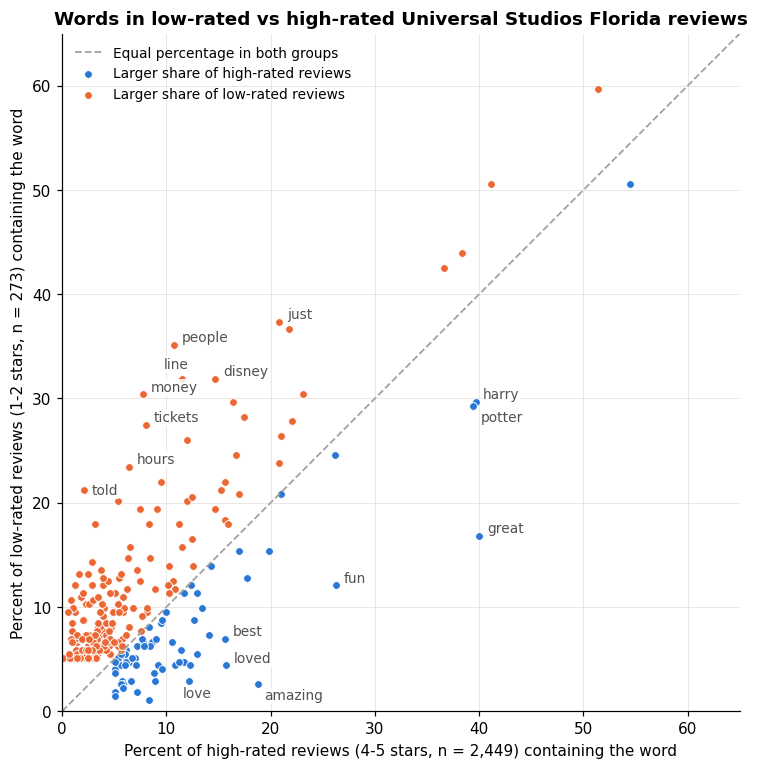

In [13]:
# Create Figure 1 with descriptive titles, readable labels, and clear units or denominators.
# Each point is a word found in at least 5% of the reviews in at least one group.
common_words = review_pct_df.loc[review_pct_df.max(axis=1) >= 5].copy()
common_words['difference'] = common_words[LOW] - common_words[HIGH]
more_low = common_words['difference'] > 0
labeled_words = pd.concat([common_words.nlargest(8, 'difference'), common_words.nsmallest(8, 'difference')])
print('Words plotted:', len(common_words))
print('Words in a larger share of low-rated reviews:', more_low.sum())
print('Words in a larger share of high-rated reviews:', (~more_low).sum())

fig, ax = plt.subplots(figsize=(8, 8))
ax.plot([0, 65], [0, 65], color=GRAY, linestyle='--', linewidth=1.2, label='Equal percentage in both groups')
ax.scatter(common_words.loc[~more_low, HIGH], common_words.loc[~more_low, LOW], s=26, color=BLUE,
           edgecolor='white', linewidth=0.6, label='Larger share of high-rated reviews')
ax.scatter(common_words.loc[more_low, HIGH], common_words.loc[more_low, LOW], s=26, color=ORANGE,
           edgecolor='white', linewidth=0.6, label='Larger share of low-rated reviews')
offsets = {'line': (-12, 7), 'told': (5, -3), 'potter': (5, -10), 'love': (-4, -11), 'amazing': (4, -10)}
for word, row in labeled_words.iterrows():
    ax.annotate(word, (row[HIGH], row[LOW]), xytext=offsets.get(word, (5, 2)), textcoords='offset points',
                fontsize=9, color=INK, bbox=dict(boxstyle='square,pad=0.1', facecolor='white', edgecolor='none', alpha=0.85))
ax.set_axisbelow(True)
ax.set(xlim=(0, 65), ylim=(0, 65), aspect='equal',
       xlabel='Percent of high-rated reviews (4-5 stars, n = 2,449) containing the word',
       ylabel='Percent of low-rated reviews (1-2 stars, n = 273) containing the word',
       title='Words in low-rated vs high-rated Universal Studios Florida reviews')
ax.grid(color='#e6e5e0', linewidth=0.6)
ax.legend(loc='upper left', frameon=False, fontsize=9)
plt.show()

**What does Figure 1 show? Describe a pattern and record at least one supporting value, identifying its word or text feature, group, and units.**

Your answer:

Most common words sit above the equal line. Of the 253 words plotted, 184 appear in a larger share of low-rated reviews and 69 in a larger share of high-rated reviews. Most of the orange words farthest above the line are about crowds, waiting, tickets, and cost. For example, "people" appears in 35.2% of low-rated reviews but only 10.7% of high-rated reviews. The blue words farthest below the line are praise words. "great" appears in 40.0% of high-rated reviews but only 16.8% of low-rated reviews. "harry" and "potter" sit below the line but stay close to 30% in low-rated reviews (29.7% and 29.3%), so low-rated reviewers still talk about the main attraction.

rating_group  Low (1-2 stars)  High (4-5 stars)  difference
word                                                       
people                   35.2              10.7        24.5
money                    30.4               7.8        22.6
line                     31.9              11.5        20.4
tickets                  27.5               8.1        19.4
told                     21.2               2.1        19.2
disney                   31.9              14.7        17.2
hours                    23.4               6.5        17.0
just                     37.4              20.8        16.5
best                      7.0              15.6        -8.6
love                      2.9              12.2        -9.2
harry                    29.7              39.6       -10.0
potter                   29.3              39.4       -10.1
loved                     4.4              15.7       -11.3
fun                      12.1              26.3       -14.2
amazing                   2.6           

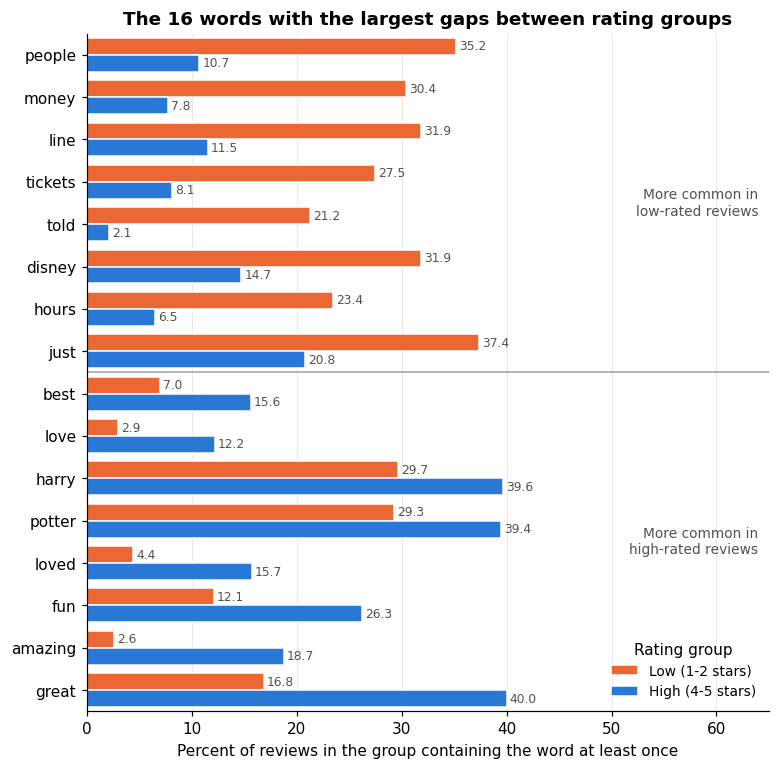

In [14]:
# Create Figure 2 using a different chart type to answer the same question.
# Label any transformation or display threshold.
# The 16 words labeled in Figure 1: the 8 with the largest gap in each direction.
bar_df = (labeled_words[[LOW, HIGH]].reset_index()
          .melt(id_vars='word', var_name='rating_group', value_name='percent_documents'))
word_order = labeled_words.sort_values('difference', ascending=False).index
print(labeled_words.sort_values('difference', ascending=False).round(1))

fig, ax = plt.subplots(figsize=(8, 8))
sns.barplot(data=bar_df, y='word', x='percent_documents', hue='rating_group', order=word_order,
            hue_order=[LOW, HIGH], palette=[ORANGE, BLUE], ax=ax, saturation=1, edgecolor='white', linewidth=1)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=2, fontsize=8, color=INK)
ax.axhline(7.5, color=GRAY, linewidth=1)
ax.text(64, 3.5, 'More common in\nlow-rated reviews', ha='right', va='center', fontsize=9, color=INK)
ax.text(64, 11.5, 'More common in\nhigh-rated reviews', ha='right', va='center', fontsize=9, color=INK)
ax.set(xlim=(0, 65), xlabel='Percent of reviews in the group containing the word at least once', ylabel='',
       title='The 16 words with the largest gaps between rating groups')
ax.legend(title='Rating group', frameon=False, loc='lower right', fontsize=9)
ax.grid(axis='x', color='#e6e5e0', linewidth=0.6)
ax.set_axisbelow(True)
plt.show()

**What does Figure 2 add? Record at least one supporting value and compare its message with Figure 1.**

Your answer:

Figure 2 gives exact values for the words with the biggest gaps, which are hard to read from the crowded corner of Figure 1. The largest gaps toward low-rated reviews are "people" (35.2% vs 10.7%, a gap of 24.5 percentage points) and "money" (30.4% vs 7.8%, 22.6 points), followed by "line", "tickets", "told", "disney", "hours", and "just". The largest gaps toward high-rated reviews are "great" (40.0% vs 16.8%, 23.2 points) and "amazing" (18.7% vs 2.6%, 16.2 points). Both figures give the same message: low-rated reviews talk about crowds, waiting, tickets, and cost, and high-rated reviews use praise words. Figure 2 makes the size of each gap clear, while Figure 1 shows that these words are the extreme ends of a much larger vocabulary that leans toward low-rated reviews overall.

#### Supplementary figure: review length by rating group

The two required figures compare vocabulary. This box plot adds review length, which affects how the word percentages should be read, because a longer review has more chances to contain any given word.

                  0.25   0.50   0.75
rating_group                        
High (4-5 stars)  40.0   69.0  133.0
Low (1-2 stars)   74.0  134.0  235.0


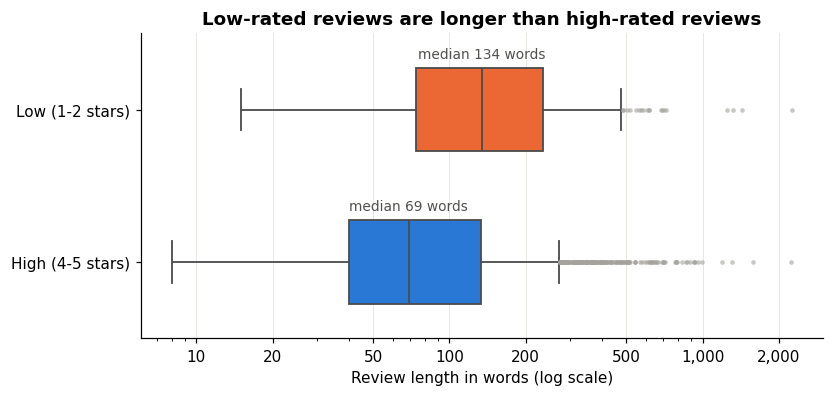

In [15]:
# Supplementary figure: review length in words for each rating group.
# The x axis uses a log scale because a few reviews run past 2,000 words.
print(rated_df.groupby('rating_group')['length_words'].quantile([0.25, 0.5, 0.75]).unstack().round(1))

fig, ax = plt.subplots(figsize=(8, 3.6))
sns.boxplot(data=rated_df, x='length_words', y='rating_group', order=[LOW, HIGH], hue='rating_group',
            hue_order=[LOW, HIGH], palette=[ORANGE, BLUE], legend=False, saturation=1, width=0.55, linewidth=1.2,
            flierprops={'marker': 'o', 'markersize': 3, 'markerfacecolor': GRAY, 'markeredgecolor': 'none',
                        'alpha': 0.6}, ax=ax)
for y, group in enumerate([LOW, HIGH]):
    median = rated_df.loc[rated_df['rating_group'] == group, 'length_words'].median()
    ax.text(median, y - 0.34, f'median {median:.0f} words', ha='center', fontsize=9, color=INK)
ax.set_xscale('log')
ax.set_xticks([10, 20, 50, 100, 200, 500, 1000, 2000])
ax.set_xticklabels(['10', '20', '50', '100', '200', '500', '1,000', '2,000'])
ax.set(xlabel='Review length in words (log scale)', ylabel='',
       title='Low-rated reviews are longer than high-rated reviews')
ax.grid(axis='x', color='#e6e5e0', linewidth=0.6)
ax.set_axisbelow(True)
plt.show()

**What does the supplementary figure add?**

Your answer:

Low-rated reviews are longer across the whole distribution, not just on average. Their median is 134 words compared with 69 for high-rated reviews, and their middle half runs from 74 to 235 words compared with 40 to 133. This supports my prediction that unhappy visitors write more to explain what went wrong. It also means Figures 1 and 2 have to be read with care. Some of the lean toward low-rated reviews in Figure 1 comes from length alone, so the words with the largest gaps are stronger evidence than the overall count of words above the line.

### Step 4: Check

Verify at least two plotted values against records or calculated summaries. Read a few original texts containing a selected word or illustrating a pattern, using the lecture's sample function or your own code. For grouped comparisons, check examples from each relevant group when matches exist. Explain whether context supports your interpretation. Do not repeat the initial missing-value count.


In [16]:
# Verify two plotted values and their denominators, if applicable.
# Recount directly from the prepared text instead of the token table.
for word, group in [('money', LOW), ('great', HIGH)]:
    in_group = rated_df.loc[rated_df['rating_group'] == group]
    has_word = in_group['prepared_text'].str.contains(rf'\b{word}\b', regex=True)
    print(f'"{word}" in {group}: {has_word.sum()} of {len(in_group)} reviews = {100 * has_word.mean():.1f}%'
          f' | plotted value {review_pct_df.loc[word, group]:.1f}%')

"money" in Low (1-2 stars): 83 of 273 reviews = 30.4% | plotted value 30.4%
"great" in High (4-5 stars): 980 of 2449 reviews = 40.0% | plotted value 40.0%


In [17]:
# Compare review lengths, because a longer review has more chances to contain any given word.
print(rated_df.groupby('rating_group')['length_words'].describe().round(1))

                   count   mean    std   min   25%    50%    75%     max
rating_group                                                            
High (4-5 stars)  2449.0  112.2  132.4   8.0  40.0   69.0  133.0  2243.0
Low (1-2 stars)    273.0  196.5  226.2  15.0  74.0  134.0  235.0  2253.0


In [18]:
# Display a few work-appropriate original texts to check meaning in context.
screened_df = rated_df.loc[~rated_df['screen_flag']]
show_examples(screened_df, 'review_text', 'rating_group', 'disney')

--- High (4-5 stars): 354 documents contain "disney"
    We've done Disney so many times with our family. Our kids are getting older,so we decided to try Universal this year. Overall we had a very good experience. A few improvements would take some of the annoyances away to make the experience go from very good to great.  First of all the entry into the park takes longer than it needs to. We had paper printed bar code tickets that took several tries to get th ...
    Oh wow! The best in Orlando......we did them all, Disney, Universal, Sea World and Busch Gardens and Universal Islands of Adventure were by far the best.  Harry Potter is the big draw and it was well worth it. The place is fantastic from Hogwarts Castle to Hogsmead, the rides, the shops and scenery and the finishing touches like the Butterbeer on sale in the street.  We all had a fantastic day and I wou ...

--- Low (1-2 stars): 85 documents contain "disney"
    ... and by the time the photos were done the people who were 

In [19]:
show_examples(screened_df, 'review_text', 'rating_group', 'money')

--- High (4-5 stars): 187 documents contain "money"
    ... than 20 minutes from our resort. Fantastic. To receive this level of service at Disney, you would need to spend at least 20K on top of being in their vacation club.  I feel that we definitely got our money’s worth at Universal and this will be our new family destination. My kids are still talking about our trip and are already planning for next year!
    ... ty quickly. However I would recommend the express pass for this side of the park. Or just go get on the other rides and usually by the time you make your way back the line is shorter and you can save money in your pocket.

--- Low (1-2 stars): 79 documents contain "money"
    ... n more disappointing is that after standing in the queue for over an hour there is little communication on what is happening and when it will resume. Feel for all the paying public that spend so much money to come and get trapped inside this ride and forego their time and even express passes at ot

In [20]:
show_examples(screened_df, 'review_text', 'rating_group', 'told')

--- High (4-5 stars): 50 documents contain "told"
    We purchased vouchers ahead of time and were told to pick up the actual tickets upon entering the park. We ASSUMED that there would be a special place to do this! Not that we could find. We stood in line almost an hour to pick up tickets we already paid for! That was the worst part of Universal[s 2 parks!
    My only negative is before going to Universal I dowloaded the app, went to book tickets, selected 1 day, 2 parks, express pass - done paid. Lined up to be told no you just ordered the express pass ($200 USD for 2) If you now want entry you need to pay $370USD more! Why would I want express but not entry!? I even went back to the app to see if I overlooked it but no it’s not clear at all. Anyway we pai ...

--- Low (1-2 stars): 57 documents contain "told"
    ... ple themed restaurants at Universal City Walk.We had four passes and paid the $10. parking fee. We went to Guest services to exchange the coupon for voucher to take to 

**Which two values did you check, and did they agree? What did the original text reveal that the figures could not? Describe any correction you made.**

Your answer:

**Values checked.** I recounted two plotted values straight from the prepared review text instead of the word table. "money" appears in 83 of 273 low-rated reviews, which is 30.4%, and "great" appears in 980 of 2,449 high-rated reviews, which is 40.0%. Both match the plotted values and use the same denominators.

**Review length.** The summary table agrees with the supplementary figure: low-rated reviews have a median of 134 words compared with 69 for high-rated reviews. A longer review has more chances to contain any word, which helps explain why 184 of the 253 plotted words lean toward low-rated reviews.

**Original text.** The examples show meaning that the figures cannot.

- "disney" is used differently in the two groups. Low-rated reviews compare Universal unfavorably, for example a reviewer who says the park charges the same prices as Disney but is not even half the fun. High-rated reviews mention Disney as a past trip or say Universal was better.
- "money" can be positive. One high-rated reviewer says they got their money's worth, so the word alone does not mean a complaint. In low-rated reviews it shows up as "a waste of money" and spending a lot to wait in a queue for a broken ride.
- "told" marks problems with tickets and staff in both groups, such as being told to pay more at the gate. Some high-rated reviews include a complaint, so a high rating does not mean the visit had no problems.

**Corrections.** Both checked values matched, so no corrections were needed.

### Step 5: Conclusion

Restate your research question, then answer it using evidence from **both** figures. Include numerical values with clear units or denominators and explain whether the evidence supports your prediction.


**Restate your question and write your conclusion.**

Your answer:

**Question.** What do visitors write about in low-rated reviews of Universal Studios Florida that they write about less often in high-rated reviews? Are low ratings driven by the attractions or by the experience around them?

**Conclusion.** Low ratings are driven mostly by the experience around the attractions, not by the attractions themselves. In Figure 2, "people" (35.2% vs 10.7%), "money" (30.4% vs 7.8%), "line" (31.9% vs 11.5%), "tickets" (27.5% vs 8.1%), and "hours" (23.4% vs 6.5%) appear in much larger shares of low-rated reviews. Figure 1 shows that "harry" and "potter" still appear in about 30% of low-rated reviews (29.7% and 29.3%), so unhappy visitors still mention the main attraction, but the words that separate the groups are about crowds, waiting, and cost. High-rated reviews are set apart by praise words, led by "great" (40.0% vs 16.8%) and "amazing" (18.7% vs 2.6%). The context check added that low-rated reviews often compare Universal unfavorably with Disney.

**Prediction.** The evidence supports most of my prediction. Waiting and cost words do lean strongly toward low-rated reviews, and the supplementary figure shows that low-rated reviews are longer (median 134 vs 69 words). Two parts were wrong. I expected Harry Potter words to mark high-rated reviews, but the gap is only about 10 points. I did not expect "people", "told", or "disney" to be among the strongest signs of a low rating.

### Step 6: Limitation

Identify **two limitations of your analysis**. Then explain which aspects of your question are easier or harder to answer from each figure.


**What are two limitations, and how do the strengths and weaknesses of your figures affect the answer?**

Your answer:

1. **The reviews are old and self-selected.** They were posted from 2004 to 2021, so they describe past visits, ticket prices, and lines, not the park today. Visitors chose to write them, and people with very good or very bad days may be more likely to post. The results describe these reviews, not all visitors.
2. **Word presence is not meaning.** Counting words ignores negation and context. "money" appears in praise ("got our money's worth") and in complaints ("a waste of money"), and "told" appears in complaints inside high-rated reviews. The longer low-rated reviews also have more chances to contain any word, so some of the lean toward low-rated reviews comes from length alone. The low-rated group is also small (273 reviews), so its percentages are less stable than the high-rated group's.

**Figures.** Figure 1 makes the overall pattern easy to see, including how many words lean each way, but its corner near zero is crowded and only 16 words are labeled. A word left off the chart, or below the 5% threshold, is not absent from the data. Figure 2 makes exact values easy to compare, but it shows only 16 words picked for having the largest gaps, so it overstates how different the typical word is. The supplementary box plot shows the length difference clearly, but it says nothing about content. Neither word figure can show what a word means in a review, which is why the context check is needed.

## Investigation 2: arXiv AI research abstracts, 2019 to 2025

### Step 1: Question

Ask one focused question about the text. Identify the documents, groups if relevant, and the vocabulary or text-derived feature you will examine. Record a prediction before producing figures.


**What is your research question, and what do you predict? Why is text analysis useful for answering it?**

Your answer:

**Question.** How did the vocabulary of AI research abstracts on arXiv change from October 2019 to October 2025? Specifically, did large language models replace older topics such as reinforcement learning and neural networks as the main subject of the field?

**Documents and groups.** One document is the abstract of one paper listed in arXiv's Artificial Intelligence category (cs.AI). The groups are four submission years: October 2019, 2021, 2023, and 2025. The feature I examine is the percent of each year's abstracts that contain a word at least once.

**Prediction.** I predict that "language", "large", and "llm" will rise sharply after 2021, with most of the change between 2021 and 2023. I predict that "reinforcement", "neural", and "learning" will fall. I expect the core words of research writing, such as "propose" and "results", to stay about the same.

**Why text analysis.** arXiv labels papers with broad categories, but the categories do not change when the field's topics do. The abstracts are the authors' own summaries, so the words they use show what the field is working on at each point in time.

### Step 2: Data

Document the source and explain what one row represents. Load a fixed copy, inspect the first and last rows and shape, use `.info()` to inspect the data storage types and non-missing values, and count missing values. Identify blank text separately from missing values.


**Give the dataset title, publisher, direct source URL, feature-definition reference, and access date. Identify your saved files.**

Your answer:

- **Title:** arXiv metadata for papers listed in cs.AI (Artificial Intelligence), first submitted in October 2019, 2021, 2023, and 2025
- **Publisher:** arXiv, operated by Cornell University. arXiv's API Terms of Use make descriptive metadata, including titles and abstracts, available under the CC0 1.0 public domain declaration (https://info.arxiv.org/help/api/tou.html).
- **Direct source URL:** The arXiv API query, for example for 2025: `https://export.arxiv.org/api/query?search_query=cat:cs.AI+AND+submittedDate:[202510010000+TO+202510312359]`. The same query was run for each year.
- **Feature-definition reference:** arXiv API User's Manual (https://info.arxiv.org/help/api/user-manual.html) for the fields, and the arXiv Category Taxonomy (https://arxiv.org/category_taxonomy) for category codes such as cs.AI.
- **Access date:** November 17, 2026.
- **Saved files:** `data/arxiv_cs_ai_abstracts_2019_2025.csv` (the 1,200-abstract sample), `data/arxiv_cs_ai_october_population_ids.csv` (IDs of all 9,079 papers the sample was drawn from), and `data/fetch_arxiv_sample.py` (the preparation code that queried the API and drew the sample).

**What does one row represent? What texts and groups are covered, and how were they collected? How did you check that the language and displayed examples are work appropriate?**

Your answer:

**One row** is one paper: its arXiv ID, submission year, first-submission time, title, abstract, main category, and all categories it is listed in.

**Coverage and collection.** I queried the arXiv API for every paper listed in cs.AI, either as its main category or cross-listed, whose first version was submitted in October of 2019, 2021, 2023, or 2025. That returned 390, 1,320, 2,523, and 4,846 papers. To keep the years comparable, `fetch_arxiv_sample.py` drew a fixed random sample of 300 papers per year with `random_state=42`. The head and tail show that many papers have a main category other than cs.AI, such as cs.LG (machine learning) or cs.CL (computation and language), so the groups describe papers that reach the AI listing, not only papers whose main field is AI. The API returns the abstract of each paper's latest version.

**Work-appropriate check.** These are research abstracts written for a technical audience. I searched them with the same screening pattern I used for the reviews and found no matches. I read every example the notebook displays, and every word on the figures is a technical or general academic word.

In [21]:
# Read dataset 2 from a relative path into a descriptive DataFrame ending in _df.
# arxiv_id is read as text so IDs such as 1910.01050 keep their final zero.
abstracts_df = pd.read_csv(DATA_DIR / 'arxiv_cs_ai_abstracts_2019_2025.csv', dtype={'arxiv_id': str})
population_df = pd.read_csv(DATA_DIR / 'arxiv_cs_ai_october_population_ids.csv', dtype={'arxiv_id': str})

In [22]:
# Display .head(), .tail(), and .shape in separate cells. Add cells as needed.
abstracts_df.head()

,arxiv_id,year,submitted,title,abstract,primary_category,categories
0,1910.00192,2019,2019-10-01T04:07:15Z,Writing habits and telltale neighbors: analyzi...,Natural language processing techniques are bei...,cs.CL,cs.CL cs.AI
1,1910.00211,2019,2019-10-01T06:16:48Z,Reinforcement Learning for Multi-Objective Opt...,This paper describes a purely data-driven solu...,cs.AI,cs.AI cs.LG eess.SY
2,1910.00246,2019,2019-10-01T08:20:56Z,MTab: Matching Tabular Data to Knowledge Graph...,"This paper presents the design of our system, ...",cs.AI,cs.AI cs.DB
3,1910.06902,2019,2019-10-01T10:18:40Z,A Unified Framework for Nonmonotonic Reasoning...,An interval-valued fuzzy answer set programmin...,cs.AI,cs.AI
4,1910.00290,2019,2019-10-01T10:26:08Z,Identifying Supporting Facts for Multi-hop Que...,Recent advances in reading comprehension have ...,cs.AI,cs.AI cs.CL cs.IR cs.LG


In [23]:
abstracts_df.tail()

,arxiv_id,year,submitted,title,abstract,primary_category,categories
1195,2511.00136,2025,2025-10-31T14:05:08Z,A Dual Large Language Models Architecture with...,Leveraging large language models (LLMs) in tra...,cs.LG,cs.LG cs.AI
1196,2510.27522,2025,2025-10-31T14:49:23Z,Leveraging Generic Time Series Foundation Mode...,Foundation models for time series are emerging...,cs.LG,cs.LG cs.AI
1197,2510.27688,2025,2025-10-31T17:58:11Z,Continuous Autoregressive Language Models,The efficiency of large language models (LLMs)...,cs.CL,cs.CL cs.AI cs.LG
1198,2511.00209,2025,2025-10-31T19:11:41Z,Diffusion Models at the Drug Discovery Frontie...,Diffusion models have emerged as a leading fra...,cs.LG,cs.LG cs.AI q-bio.BM q-bio.QM
1199,2511.00280,2025,2025-10-31T21:58:31Z,Calibration Across Layers: Understanding Calib...,Large Language Models (LLMs) have demonstrated...,cs.LG,cs.LG cs.AI cs.CL


In [24]:
abstracts_df.shape

(1200, 7)

In [25]:
# Use .info() to inspect the data storage types and non-missing values.
abstracts_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   arxiv_id          1200 non-null   object
 1   year              1200 non-null   int64 
 2   submitted         1200 non-null   object
 3   title             1200 non-null   object
 4   abstract          1200 non-null   object
 5   primary_category  1200 non-null   object
 6   categories        1200 non-null   object
dtypes: int64(1), object(6)
memory usage: 65.8+ KB


In [26]:
# Count missing values in every feature and identify blank text.
print(abstracts_df.isna().sum())
blank_abstracts = abstracts_df['abstract'].fillna('').str.strip().eq('')
print('Blank abstracts:', blank_abstracts.sum())

arxiv_id            0
year                0
submitted           0
title               0
abstract            0
primary_category    0
categories          0
dtype: int64
Blank abstracts: 0


**Complete the table for every feature used in the question, preparation, or figures. Add rows as needed.**

Your answer:

| Feature | Meaning and units or codes | Feature type | Data storage type | Missing values |
| --- | --- | --- | --- | --- |
| `arxiv_id` | arXiv identifier without the version number, such as `2510.27688` | Categorical (identifier) | object | 0 |
| `year` | Year of first submission. All papers were first submitted in October of that year | Temporal (used as the group) | int64 | 0 |
| `submitted` | Time of first submission, ISO 8601 in UTC | Temporal | object | 0 |
| `abstract` | Original abstract text, with line breaks collapsed to single spaces | Text | object | 0 (0 blank) |
| `primary_category` | The paper's main arXiv category, such as `cs.AI` or `cs.LG` | Categorical | object | 0 |
| `categories` | Every arXiv category the paper is listed in, separated by spaces | Categorical | object | 0 |
| `prepared_text` (created) | Abstract with inline LaTeX math removed, then prepared as in Investigation 1 | Text | object | 0 |
| `length_words` (created) | Number of words in the original abstract, split on spaces | Quantitative | int64 | 0 |
| `word` (in `abstract_tokens_df`) | One retained word occurrence after stopword removal | Text | object | 0 |
| Percent of abstracts containing the word (in `abstract_pct_df`) | Abstracts in the year with the word at least once, divided by that year's 300 abstracts, times 100 | Quantitative | float64 | 0 |

**Which records and features will you use? Explain your groups, sampling, missing or blank text, duplicates, content screening, and text-preparation decisions, including stopwords.**

Your answer:

- **Records and groups.** I use all 1,200 sampled abstracts. The groups are the four submission years, with 300 abstracts each.
- **Sampling.** The number of cs.AI papers grew from 390 in October 2019 to 4,846 in October 2025. Sampling 300 per year with a fixed seed (`random_state=42`) keeps each year's denominator equal and keeps the 2025 papers from dominating any pooled ranking. The full ID list is saved, and the notebook confirms that all 1,200 sampled IDs are in it.
- **Missing, blank, and duplicate text.** There are no missing values, no blank abstracts, no repeated IDs, and no repeated abstracts in the sample.
- **Content screening.** No exclusions were needed, as described above.
- **Text preparation.** I first remove inline LaTeX math written between dollar signs, which appears in 69 abstracts, because it is notation rather than words. Then I use the same `prepare_text` and `make_tokens` functions as Investigation 1. Hyphenated terms split into separate words, so "fine-tuning" becomes "fine" and "tuning".
- **Stopwords.** I use `ENGLISH_STOP_WORDS` plus the same contraction list. I add no dataset-specific stopwords. Words such as "paper" and "propose" are part of how abstracts are written, and whether they change over time is part of the question.

In [27]:
# Preserve original text and document IDs. Prepare text and calculated features.
# Report original and retained row counts and the number of documents in each group.
print('Original rows:', len(abstracts_df))
print('Duplicate arXiv IDs:', abstracts_df['arxiv_id'].duplicated().sum())
print('Duplicate abstracts:', abstracts_df['abstract'].duplicated().sum())
print('Papers in the saved population list:', len(population_df))
print('Sampled IDs found in the saved population list:', abstracts_df['arxiv_id'].isin(population_df['arxiv_id']).sum())
pd.DataFrame({'October submissions listed in cs.AI': population_df.groupby('year').size(),
              'Sampled abstracts': abstracts_df.groupby('year').size()})

Original rows: 1200
Duplicate arXiv IDs: 0
Duplicate abstracts: 0
Papers in the saved population list: 9079
Sampled IDs found in the saved population list: 1200


,October submissions listed in cs.AI,Sampled abstracts
year,,
2019,390,300
2021,1320,300
2023,2523,300
2025,4846,300


In [28]:
# Remove inline LaTeX math ($...$), which is notation rather than words, then prepare as in Investigation 1.
print('Abstracts matching the Investigation 1 screening pattern:',
      abstracts_df['abstract'].str.lower().str.contains(SCREEN_PATTERN, regex=True).sum())
print('Abstracts containing $ signs:', abstracts_df['abstract'].str.contains('$', regex=False).sum())
abstracts_df['prepared_text'] = prepare_text(abstracts_df['abstract'].str.replace(r'\$[^$]*\$', ' ', regex=True))
abstracts_df['length_words'] = abstracts_df['abstract'].str.split().str.len()
print('Median abstract length in words:')
print(abstracts_df.groupby('year')['length_words'].median())

Abstracts matching the Investigation 1 screening pattern: 0
Abstracts containing $ signs: 69


Median abstract length in words:
year
2019    161.0
2021    162.5
2023    173.0
2025    179.0
Name: length_words, dtype: float64


In [29]:
# No dataset-specific stopwords: words such as "paper" and "propose" are part of how abstracts are written,
# and whether they change over time is part of the question.
ARXIV_STOPWORDS = []
abstract_tokens_df = make_tokens(abstracts_df, 'arxiv_id', 'year', ARXIV_STOPWORDS)
abstract_pct_df = percent_documents(abstract_tokens_df, abstracts_df, 'arxiv_id', 'year')
print('Retained word occurrences:', len(abstract_tokens_df))
print('Distinct retained words:', abstract_tokens_df['word'].nunique())
abstract_tokens_df.head()

Retained word occurrences:

 129094
Distinct retained words: 11073


,arxiv_id,year,word
0,1910.00192,2019,natural
1,1910.00192,2019,language
2,1910.00192,2019,processing
3,1910.00192,2019,techniques
4,1910.00192,2019,applied


**How many records were removed from the dataset? Explain why, and state what one row represents in each analysis table.**

Your answer:

No records were removed from the saved sample of 1,200 abstracts, because none were missing, blank, or duplicated. The reduction happened earlier, during sampling: 9,079 papers matched the query and 1,200 (300 per year) were kept, as documented in the preparation script and the population ID file.

- In `abstracts_df`, one row is one sampled paper (1,200 rows).
- In `population_df`, one row is one paper that matched the query, with only its ID and year (9,079 rows).
- In `abstract_tokens_df`, one row is one retained word occurrence in one abstract (129,094 rows covering 11,073 distinct words).
- In `abstract_pct_df`, one row is one word, with the percent of each year's abstracts that contain it.

### Step 3: Evidence

Create two different figure types that answer this same question. At least one must support a numerical comparison. Use consistent preparation and explain any difference in the records or words displayed.


**Which two chart types will you use, and what should each make easier to answer? Specify what positions, colors, and sizes represent and define any percentage denominator.**

Your answer:

Both figures use the percent of abstracts in a year that contain the word at least once. The denominator is that year's 300 sampled abstracts, including abstracts without the word.

**Figure 1: word-by-year heatmap.** Rows are the 15 words found in the most abstracts across all four years combined, and columns are the four years. Each cell's color shows the percent of that year's abstracts containing the word on one blue scale from 0% to 70%, and each cell is labeled with its value. This figure shows how the field's most common words changed and whether the change was gradual or happened in one jump.

**Figure 2: diverging horizontal bar chart.** It shows the change from 2019 to 2025 in percentage points for the 10 words that rose most and the 10 that fell most, among words found in at least 5% of abstracts in 2019 or 2025. Bar length and direction show the change. Blue bars rose and orange bars fell. This figure finds the biggest shifts, including words that are not common enough to be in Figure 1.

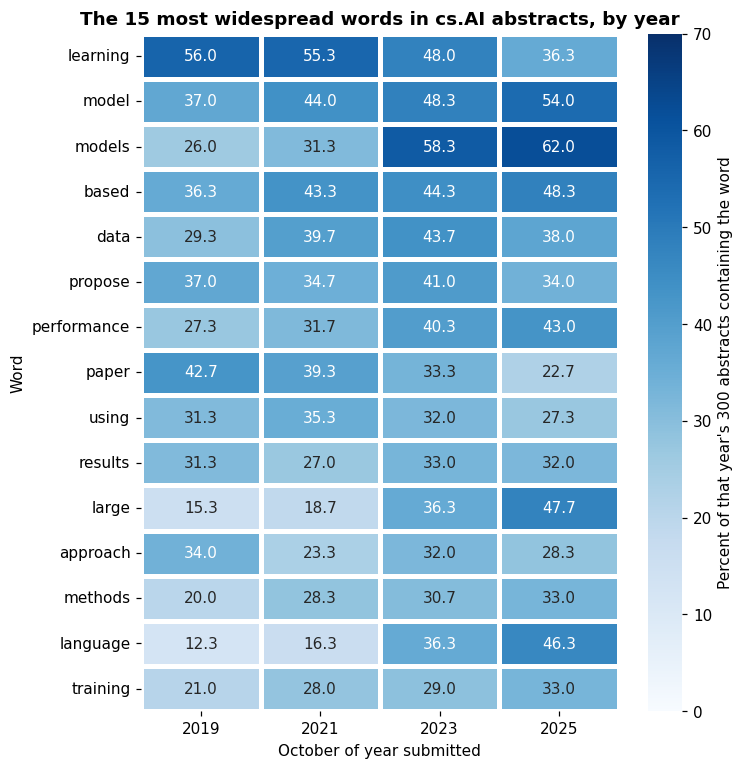

In [30]:
# Create Figure 1 with descriptive titles, readable labels, and clear units or denominators.
# Rows: the 15 words found in the most abstracts across all four years (each year has 300 abstracts).
YEARS = [2019, 2021, 2023, 2025]
top_words = abstract_tokens_df.groupby('word')['arxiv_id'].nunique().nlargest(15).index
heat_df = abstract_pct_df.reindex(index=top_words, columns=YEARS).fillna(0)

fig, ax = plt.subplots(figsize=(7, 8))
sns.heatmap(heat_df, annot=True, fmt='.1f', cmap='Blues', vmin=0, vmax=70, linewidths=2, linecolor='white',
            cbar_kws={'label': 'Percent of that year\'s 300 abstracts containing the word'}, ax=ax)
ax.set(xlabel='October of year submitted', ylabel='Word',
       title='The 15 most widespread words in cs.AI abstracts, by year')
ax.tick_params(axis='y', rotation=0)
plt.show()

**What does Figure 1 show? Describe a pattern and record at least one supporting value, identifying its word or text feature, group, and units.**

Your answer:

The heatmap shows a jump between 2021 and 2023. "language" appears in 12.3% of 2019 abstracts and 16.3% of 2021 abstracts, then 36.3% in 2023 and 46.3% in 2025. "large" follows the same path, from 15.3% to 47.7%. "models" rises from 26.0% to 62.0%, the highest value in the 2025 column. Going the other way, "learning" falls from 56.0% of abstracts in 2019 to 36.3% in 2025, and "paper" falls from 42.7% to 22.7%. Words like "results" stay about the same (31.3% in 2019 and 32.0% in 2025).

Words ranked: 478
year           2019  2021  2023  2025  change
word                                         
models         26.0  31.3  58.3  62.0    36.0
language       12.3  16.3  36.3  46.3    34.0
large          15.3  18.7  36.3  47.7    32.3
llms            0.0   0.0  18.0  27.0    27.0
existing       13.0  20.3  24.7  37.7    24.7
framework      23.3  17.7  20.3  46.3    23.0
introduce      10.0  12.0  22.0  32.7    22.7
llm             0.0   0.0   9.0  21.0    21.0
accuracy        7.0  13.0  17.3  25.0    18.0
high           13.0  18.0  17.3  30.7    17.7
neural         20.0  31.0  14.0   8.3   -11.7
reinforcement  27.0  13.3  10.0  15.0   -12.0
algorithms     16.3  15.0  12.3   4.3   -12.0
different      24.3  22.3  22.7  11.7   -12.7
learn          17.7  12.0   8.3   4.3   -13.3
proposed       26.7  26.0  18.7  11.0   -15.7
problem        27.3  19.0  16.3  11.0   -16.3
algorithm      21.7  14.3  11.0   5.0   -16.7
learning       56.0  55.3  48.0  36.3   -19.7
paper          4

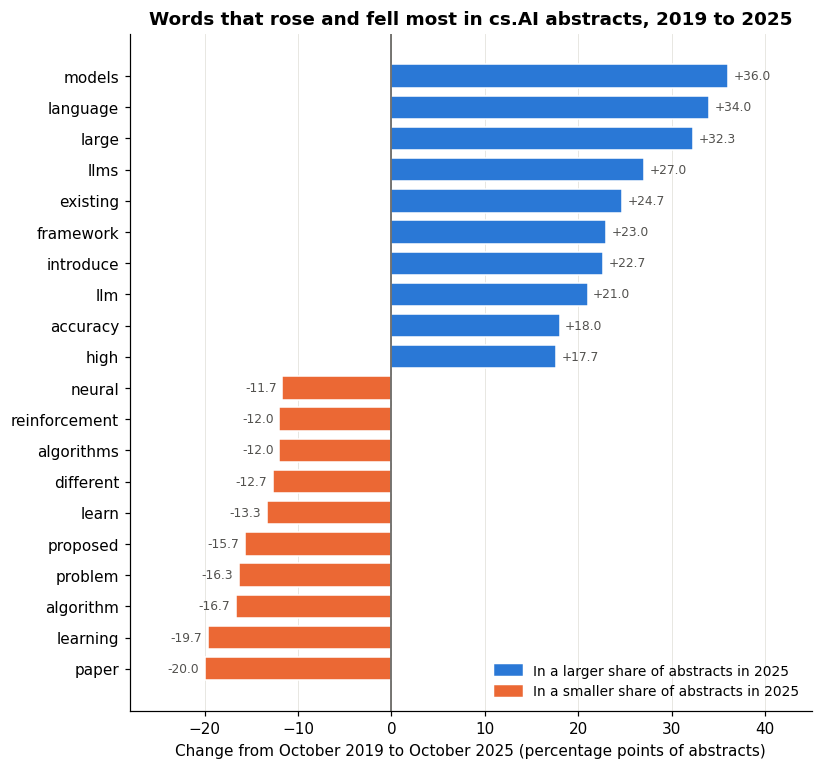

In [31]:
# Create Figure 2 using a different chart type to answer the same question.
# Label any transformation or display threshold.
# Change = percent of 2025 abstracts minus percent of 2019 abstracts containing the word (percentage points).
# Only words found in at least 5% of abstracts in 2019 or 2025 are ranked.
change_df = abstract_pct_df.reindex(columns=YEARS).fillna(0)
change_df = change_df.loc[change_df[[2019, 2025]].max(axis=1) >= 5].copy()
change_df['change'] = change_df[2025] - change_df[2019]
shift_df = pd.concat([change_df.nlargest(10, 'change'), change_df.nsmallest(10, 'change')]).sort_values('change')
print('Words ranked:', len(change_df))
print(shift_df.sort_values('change', ascending=False).round(1))

fig, ax = plt.subplots(figsize=(8, 8))
colors = np.where(shift_df['change'] > 0, BLUE, ORANGE)
ax.barh(shift_df.index, shift_df['change'], color=colors, edgecolor='white', linewidth=1, height=0.75)
for y, value in enumerate(shift_df['change']):
    ax.text(value + (0.6 if value > 0 else -0.6), y, f'{value:+.1f}', va='center',
            ha='left' if value > 0 else 'right', fontsize=8, color=INK)
ax.axvline(0, color=INK, linewidth=1)
ax.set(xlim=(-28, 45), xlabel='Change from October 2019 to October 2025 (percentage points of abstracts)',
       ylabel='', title='Words that rose and fell most in cs.AI abstracts, 2019 to 2025')
ax.grid(axis='x', color='#e6e5e0', linewidth=0.6)
ax.set_axisbelow(True)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
          labels=['In a larger share of abstracts in 2025', 'In a smaller share of abstracts in 2025'],
          loc='lower right', frameon=False, fontsize=9)
plt.show()

**What does Figure 2 add? Record at least one supporting value and compare its message with Figure 1.**

Your answer:

Figure 2 ranks the biggest shifts directly, and it adds words that are too rare to make Figure 1. "llms" rose by 27.0 percentage points and "llm" by 21.0 points, from 0.0% of abstracts in 2019 to 27.0% and 21.0% in 2025. Writing words rose as well: "existing" (+24.7 points), "framework" (+23.0), and "introduce" (+22.7). On the falling side, "reinforcement" dropped 12.0 points (27.0% to 15.0%), "neural" dropped 11.7 points, and "algorithm" dropped 16.7 points. Both figures tell the same story about language models, but Figure 2 shows that the older vocabulary that fell was about algorithms, reinforcement learning, and neural networks, while Figure 1 shows that the core vocabulary of research writing mostly held steady.

### Step 4: Check

Verify at least two plotted values against records or calculated summaries. Read a few original texts containing a selected word or illustrating a pattern, using the lecture's sample function or your own code. For grouped comparisons, check examples from each relevant group when matches exist. Explain whether context supports your interpretation. Do not repeat the initial missing-value count.


In [32]:
# Verify two plotted values and their denominators, if applicable.
for word, year in [('llms', 2025), ('learning', 2019)]:
    in_year = abstracts_df.loc[abstracts_df['year'] == year]
    has_word = in_year['prepared_text'].str.contains(rf'\b{word}\b', regex=True)
    print(f'"{word}" in {year}: {has_word.sum()} of {len(in_year)} abstracts = {100 * has_word.mean():.1f}%'
          f' | plotted value {abstract_pct_df.loc[word, year]:.1f}%')

"llms" in 2025: 81 of 300 abstracts = 27.0% | plotted value 27.0%
"learning" in 2019: 168 of 300 abstracts = 56.0% | plotted value 56.0%


In [33]:
# "llm" and "llms" are counted as separate words, and the phrase "large language model" spans three words.
# Count abstracts that use any of these forms in each year.
llm_pattern = r'\bllms?\b|\blarge language models?\b'
print((100 * abstracts_df['prepared_text'].str.contains(llm_pattern, regex=True)
       .groupby(abstracts_df['year']).mean()).round(1))

year
2019     0.0
2021     0.0
2023    24.7
2025    41.7
Name: prepared_text, dtype: float64


In [34]:
# Display a few work-appropriate original texts to check meaning in context.
both_ends_df = abstracts_df.loc[abstracts_df['year'].isin([2019, 2025])]
show_examples(both_ends_df, 'abstract', 'year', 'reinforcement', n=1)

--- 2019: 81 documents contain "reinforcement"
    ...  such as language modeling and machine translation. Harnessing the transformer's ability to process long time horizons of information could provide a similar performance boost in partially observable reinforcement learning (RL) domains, but the large-scale transformers used in NLP have yet to be successfully applied to the RL setting. In this work we demonstrate that the standard transformer architecture is di ...

--- 2025: 45 documents contain "reinforcement"
    ... te new intermediate pose skeletons, which are then optimized for collision-free configurations and retargeted to the humanoid before integration into a simulated environment for policy adaptation via reinforcement learning. Experimental evaluations on the CMU MoCap dataset demonstrate that our method consistently outperforms baselines, achieving superior performance across metrics. Our code is available at: ht ...



In [35]:
show_examples(both_ends_df, 'abstract', 'year', 'paper', n=1)

--- 2019: 128 documents contain "paper"
    ... bility to predict hundreds of possible simulation outcomes (e.g., under different environment and crowd situations) at real-time rates, for which these approaches are prohibitively expensive. In this paper, we propose an approach to instantly predict the long-term flow of crowds in arbitrarily large, realistic environments. Central to our approach is a novel CAGE representation consisting of Capacity,  ...

--- 2025: 68 documents contain "paper"
    ... ironment and answer questions without explicit thinking or planning, which limits their reasoning ability and results in excessive or inefficient exploration as well as ineffective responses. In this paper, we introduce ToolEQA, an agent that integrates external tools with multi-step reasoning, where external tools can provide more useful information for completing the task, helping the model derive be ...



**Which two values did you check, and did they agree? What did the original text reveal that the figures could not? Describe any correction you made.**

Your answer:

**Values checked.** I recounted two plotted values directly from the prepared abstracts. "llms" appears in 81 of 300 abstracts from 2025, which is 27.0%, and "learning" appears in 168 of 300 abstracts from 2019, which is 56.0%. Both match the plotted values and use the same denominator.

**Combined LLM forms.** The figures count "llm" and "llms" as different words and cannot see the three-word phrase "large language model". I counted abstracts that use any of these forms: 0.0% in 2019 and 2021, 24.7% in 2023, and 41.7% in 2025. The topic is more widespread than either single word in Figure 2 suggests.

**Original text.**

- "reinforcement" means reinforcement learning in both years, but the role changed. The 2019 example is about the method itself, applying transformers to reinforcement learning problems. The 2025 example uses reinforcement learning as one step inside a robotics system. The figure shows the word becoming less common, and the context suggests it also moved from topic to tool.
- "paper" is used in "In this paper, we propose..." in 2019 and "In this paper, we introduce..." in 2025. Its decline reflects a change in writing style, not a change in research topic, which matches the rise of "introduce" in Figure 2.

**Corrections.** Both checked values matched, so no corrections were needed.

### Step 5: Conclusion

Restate your research question, then answer it using evidence from **both** figures. Include numerical values with clear units or denominators and explain whether the evidence supports your prediction.


**Restate your question and write your conclusion.**

Your answer:

**Question.** How did the vocabulary of AI research abstracts on arXiv change from October 2019 to October 2025, and did large language models replace older topics as the main subject of the field?

**Conclusion.** Language models became the field's most widespread subject, and the change happened mostly between 2021 and 2023. In Figure 1, "language" rises from 16.3% of abstracts in 2021 to 36.3% in 2023 and 46.3% in 2025, and "models" rises from 26.0% in 2019 to 62.0% in 2025. In Figure 2, "llms" (+27.0 points) and "llm" (+21.0 points) are among the largest increases, and any form of "LLM" or "large language model" appears in 41.7% of 2025 abstracts compared with 0.0% in 2019. Older vocabulary fell but did not disappear. "learning" dropped from 56.0% to 36.3%, "reinforcement" from 27.0% to 15.0%, and "neural" by 11.7 points. The context check shows reinforcement learning is still used in 2025, but more often as a step inside a larger system.

**Prediction.** The evidence supports my prediction about language models and its timing, and the decline of "reinforcement", "neural", and "learning". I was partly wrong about the core writing words. "results" stayed steady, but "paper" (-20.0 points) and "proposed" (-15.7 points) fell while "introduce" (+22.7 points) rose, so the way abstracts are written also changed.

### Step 6: Limitation

Identify **two limitations of your analysis**. Then explain which aspects of your question are easier or harder to answer from each figure.


**What are two limitations, and how do the strengths and weaknesses of your figures affect the answer?**

Your answer:

1. **The sample does not represent all AI research.** It covers one month in each of four years and only papers that reach the cs.AI listing, including many cross-listed from machine learning and language fields. The listing grew from 390 to 4,846 papers in October, so the 2025 group comes from a much larger and more varied pool. A shift in which fields cross-list to cs.AI could look like a shift in topics. The abstracts are also from each paper's latest version, which may have been edited after October.
2. **Single words split and blur topics.** "llm" and "llms" are counted separately, "large language model" is three words, and hyphenated terms such as "fine-tuning" are split, so some topics are undercounted in the figures. Some words have more than one meaning, and some changes, like the drop in "paper", reflect writing style rather than research topic.

**Figures.** The heatmap makes the timing easy to see because it shows all four years, but it only includes the 15 most widespread words, so a fast-growing but less common word like "llms" is not in it. The diverging bar chart finds those words, but it compares only 2019 and 2025, so it hides when each change happened and whether it went up and down in between. Using both figures together is what shows both the size and the timing of the change.

## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:

Yes. I used Claude, an AI assistant, to help write and debug the preparation and plotting code and to draft my written answers, which I checked against the notebook output.

One suggestion I checked was to describe the arXiv abstracts as public domain. Before accepting it, I read arXiv's API Terms of Use, which say that descriptive metadata, including abstracts, is available under the CC0 1.0 public domain declaration, while the full papers are not. I accepted the claim for the abstracts only, not the full papers, and cited the terms page in my source documentation.

## Submission checklist

- Include two distinct text datasets and document their sources, feature definitions, collection context, and access dates.
- Review the datasets and displayed language for work appropriateness; document any screening and its effects.
- Ask one research question per dataset and complete all six steps for each question.
- Complete both feature tables and every written response.
- Include four finished figures: two different chart types per question, with at least one numerical comparison per pair.
- Explain text preparation, stopwords, filtering, missing or blank text, duplicates, group sizes, and row counts.
- Define what is counted and the denominator of every percentage.
- Check two plotted values and original text context for each investigation.
- Restate each question in its conclusion and cite evidence from both figures.
- Identify two limitations per investigation and compare what the displays reveal or obscure.
- Include your data files and any preparation code using relative paths. Complete the AI-use reflection, restart the kernel, and run cells in order before submitting.
